# Review Sentiment: Rebuilding the Foundations

*An AI-assisted revision of my M.S. Data Analytics coursework (WGU), [D213 Task 2: sentiment analysis with a neural network](../../D213-advanced-data-analytics/), worked through with Claude (Anthropic).*

**Question:** can the sentiment of a short customer review, positive or negative, be predicted from its text?

## How this notebook was made

This revision was done as a learning walkthrough, one concept at a time. Claude explained each idea, wrote the code and ran the experiments. I asked questions until each step made sense, made the decisions, and then wrote what I had understood. Those passages are marked **In my words**. The rest of the text describes what the code does and what it found.

The original notebook, as submitted, is kept unchanged in its course folder. The [README](README.md) records the decisions I made along the way.

**Status:** in progress. Sections 1 and 2 are complete. The neural network sections are still to come.

In [1]:
import csv
import re
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline

for resource in ("punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"):
    nltk.download(resource, quiet=True)

pd.set_option("display.precision", 3)
pd.set_option("display.max_colwidth", 90)
SEED = 31337  # the seed used in the original notebook

INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK_2, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "legend.frameon": False, "font.size": 10,
})

## 1. Loading the data

The data is the *Sentiment Labelled Sentences* set from the UCI Machine Learning Repository (Kotzias et al., 2015): 1,000 reviews each from Amazon, IMDb and Yelp. Each line of a file holds one review, a tab, and a label: 1 for positive, 0 for negative.

The first cell loads the files the way the original notebook did. The second counts the lines in each file.

In [2]:
DATA = "../../D213-advanced-data-analytics/data/"
FILES = {"Amazon": "amazon_cells_labelled.txt", "IMDb": "imdb_labelled.txt", "Yelp": "yelp_labelled.txt"}
COLUMNS = dict(delimiter="\t", header=None, names=["review", "sentiment"])

as_originally_loaded = {source: pd.read_csv(DATA + name, **COLUMNS) for source, name in FILES.items()}
lines_in_file = {source: sum(1 for _ in open(DATA + name, encoding="utf-8")) for source, name in FILES.items()}

pd.DataFrame({"lines in the file": lines_in_file,
              "rows loaded by the original code": {s: len(d) for s, d in as_originally_loaded.items()}})

,lines in the file,rows loaded by the original code
Amazon,1000,1000
IMDb,1000,748
Yelp,1000,1000


The IMDb file has 1,000 lines, but only 748 rows were loaded. The longest "reviews" in that load show where the rest went:

In [3]:
imdb = as_originally_loaded["IMDb"]
merged = imdb[imdb["review"].str.contains("\n")]
print(f"Rows that contain line breaks: {len(merged)}")
print(f"Reviews run together inside each of them: {merged['review'].str.count(chr(10)).tolist()}  "
      f"(total {merged['review'].str.count(chr(10)).sum()})")
print(f"Longest row: {imdb['review'].str.split(' ').str.len().max():,} words\n")

lines = open(DATA + FILES["IMDb"], encoding="utf-8").read().split("\n")
print(f"Lines in the file with an unmatched quotation mark: {sum(line.count(chr(34)) % 2 == 1 for line in lines)}")
print("File line 20:", repr(lines[19]))

Rows that contain line breaks: 5
Reviews run together inside each of them: [61, 15, 97, 25, 54]  (total 252)
Longest row: 1,393 words

Lines in the file with an unmatched quotation mark: 10
File line 20: '" The structure of this film is easily the most tightly constructed in the history of cinema.  \t1'


By default, `pandas.read_csv` treats a quotation mark at the start of a field as the start of a *quoted* field and keeps reading, across line breaks, until it finds a closing quotation mark. That is how CSV files store text containing commas or newlines. These files aren't written that way: line 20 opens with a quotation mark that never closes, so everything up to the next stray quotation mark was read as one review. Each of those merged rows also received a single label, whatever the labels of the reviews inside it.

The fix is to tell pandas that quotation marks are ordinary characters.

In [4]:
frames = []
for source, name in FILES.items():
    frame = pd.read_csv(DATA + name, quoting=csv.QUOTE_NONE, **COLUMNS)
    frame["source"] = source
    frames.append(frame)
reviews = pd.concat(frames, ignore_index=True)

assert len(reviews) == sum(lines_in_file.values())  # row count checked against the source files
print(f"{len(reviews):,} reviews loaded; longest is {reviews['review'].str.split().str.len().max()} words")

duplicated = reviews[reviews.duplicated("review", keep=False)]
print(f"Exact duplicate texts: {reviews.duplicated('review').sum()} "
      f"(with conflicting labels: {duplicated.groupby('review')['sentiment'].nunique().gt(1).sum()})")
reviews = reviews.drop_duplicates("review").reset_index(drop=True)
print(f"After dropping duplicates: {len(reviews):,} reviews, {reviews['sentiment'].mean():.1%} positive")
reviews.groupby("source")["sentiment"].agg(reviews="size", share_positive="mean")

3,000 reviews loaded; longest is 71 words
Exact duplicate texts: 17 (with conflicting labels: 0)
After dropping duplicates: 2,983 reviews, 49.9% positive


,reviews,share_positive
source,,
Amazon,990,0.498
IMDb,997,0.499
Yelp,996,0.501


Duplicates are dropped so that the same review can't appear in both the training data and the test data.

> **In my words**
>
> The issue with the IMDB dataset comes down to improperly ingesting the data; the reviews were not sufficiently parsed, leading to instances where multiple reviews were combined into a single, massive review. There were several stages where this should have been caught, including when the row count for the IMDB dataset was suspiciously low, and when there were instances of ridiculously long (1300+ word) reviews, that I inappropriately treated as simple outliers rather than properly investigating the cause. The biggest lesson from this for me is to maintain an eye for detail and stop treating routine steps like data ingestion as boxed, repeatable tasks.

## 2. A baseline that counts words

Before any neural network, a simple model sets the standard to beat, and gives a way to measure what each data-cleaning step does.

### Splitting the data

70% of the reviews are used for training, 15% for validation (comparing models along the way) and 15% for testing (used once, at the end). The split keeps the same mix of sources and labels in each part. Everything in this section uses the training set only.

In [5]:
strata = reviews["source"] + reviews["sentiment"].astype(str)
train, rest = train_test_split(reviews, train_size=0.70, random_state=SEED, stratify=strata)
validation, test = train_test_split(rest, test_size=0.50, random_state=SEED, stratify=strata[rest.index])
print(f"Training: {len(train):,}   Validation: {len(validation):,}   Test: {len(test):,}")

Training: 2,088   Validation: 447   Test: 448


### How the model works

> **In my words**
>
> The words in the review are assigned a position; these have no implied relationship to one another. Each review is then turned into a row of numbers in each position, with the value of each column showing the number of times that column's word appears in that review. The row length for each review matches the total vocabulary length of the training dataset. For larger datasets, the vocabulary might be reduced through a few different methods, but in this case the vocabulary length is not prohibitively large. Word order is not considered, just the presence and frequency of individual words within reviews.
>
> Words are weighted based on their commonality, with common words receiving lower weights and uncommon or infrequent words having higher weights; the assumption here is that the rarer the word, the more likely it is that it tells you something about the document being analyzed, whereas common words ("the", "and", etc.) are less likely to be indicators of meaning.
>
> Logistic regression is then used to produce coefficients for each word, based on the labelled training reviews, showing each word's effect on outcome - a positive coefficient shows a shift towards positive reviews, a negative coefficient towards negative reviews, etc. For each review, the model multiplies the weight of each word by the coefficient determined by the regression, then adds the results up and converts the review total into a probability that the review is a positive one.

The weighting described in the second paragraph is called TF-IDF. The example below shows two reviews as the model sees them: only the words each one contains have a non-zero value.

In [6]:
WORDS = r"(?u)\b\w+\b"  # every run of letters or digits counts as a word, including one-letter words

demo = TfidfVectorizer(token_pattern=WORDS).fit(train["review"])
row = demo.transform(["Great phone, great price.", "Not great."])
vocabulary = demo.get_feature_names_out()
print(f"Vocabulary: {len(vocabulary):,} words, so each review is a row of {len(vocabulary):,} numbers")
for i, text in enumerate(["Great phone, great price.", "Not great."]):
    nonzero = {vocabulary[j]: round(row[i, j], 2) for j in row[i].nonzero()[1]}
    print(f"  {text!r:28} -> {nonzero}; every other position is 0")

Vocabulary: 4,204 words, so each review is a row of 4,204 numbers
  'Great phone, great price.'  -> {'great': np.float64(0.74), 'phone': np.float64(0.39), 'price': np.float64(0.55)}; every other position is 0
  'Not great.'                 -> {'great': np.float64(0.74), 'not': np.float64(0.67)}; every other position is 0


### What each cleaning step does

The original notebook cleaned the text in four steps: lowercase, remove punctuation and digits, lemmatize (reduce each word to a base form), and remove stopwords (very common words). The function below can switch each step on or off. It also has an option to **protect negations**: contractions such as "wouldn't" are expanded to "would not", and "not", "no", "nor" and "never" are kept even when other stopwords are removed.

In [7]:
STOPWORDS = set(stopwords.words("english"))
NEGATIONS = {"not", "no", "nor", "never"}
lemmatizer = nltk.WordNetLemmatizer()
print(f"NLTK's English stopword list has {len(STOPWORDS)} words. Negations in it: "
      f"{sorted(w for w in STOPWORDS if w in NEGATIONS or w.endswith(chr(39) + 't'))[:12]} ...")


def clean(text, lower=True, strip=True, lemmatize=True, remove_stopwords=True, protect_negations=False):
    if lower:
        text = text.lower()
    if protect_negations:
        text = re.sub(r"\bcan't\b", "can not", text, flags=re.I)
        text = re.sub(r"\bwon't\b", "will not", text, flags=re.I)
        text = re.sub(r"n't\b", " not", text, flags=re.I)
    if strip:
        text = re.sub("[^a-zA-Z]", " ", text)
    words = word_tokenize(text)
    if lemmatize:
        words = [lemmatizer.lemmatize(w) for w in words]
    if remove_stopwords:
        drop = STOPWORDS - NEGATIONS if protect_negations else STOPWORDS
        words = [w for w in words if w.lower() not in drop]
    return " ".join(words)


VARIANTS = {
    "0. No cleaning": dict(lower=False, strip=False, lemmatize=False, remove_stopwords=False),
    "1. Lowercase": dict(strip=False, lemmatize=False, remove_stopwords=False),
    "2. + punctuation and digits removed": dict(lemmatize=False, remove_stopwords=False),
    "3. + lemmatized": dict(remove_stopwords=False),
    "4. + stopwords removed (the original cleaning)": dict(),
    "5. The original cleaning, negations protected": dict(protect_negations=True),
}

example = "Overall, I was not impressed and wouldn't go back."
folds = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)


def baseline(vectorizer=None):
    return make_pipeline(vectorizer or TfidfVectorizer(token_pattern=WORDS, lowercase=False), LogisticRegression(max_iter=2000))


rows = {}
for name, options in VARIANTS.items():
    text = train["review"].map(lambda r: clean(r, **options))
    accuracy = cross_val_score(baseline(), text, train["sentiment"], cv=folds)
    rows[name] = {"accuracy": accuracy.mean(), "± across folds": accuracy.std(),
                  "vocabulary": len(TfidfVectorizer(token_pattern=WORDS, lowercase=False).fit(text).vocabulary_),
                  "the example review becomes": clean(example, **options)}
print("Example review:", repr(example))
cleaning_table = pd.DataFrame(rows).T
cleaning_table

NLTK's English stopword list has 198 words. Negations in it: ["aren't", "couldn't", "didn't", "doesn't", "don't", "hadn't", "hasn't", "haven't", "isn't", "mightn't", "mustn't", "needn't"] ...


Example review: "Overall, I was not impressed and wouldn't go back."


,accuracy,± across folds,vocabulary,the example review becomes
0. No cleaning,0.787,0.015,4756,"Overall , I was not impressed and would n't go back ."
1. Lowercase,0.808,0.016,4192,"overall , i was not impressed and would n't go back ."
2. + punctuation and digits removed,0.808,0.015,4132,overall i was not impressed and wouldn t go back
3. + lemmatized,0.806,0.018,3814,overall i wa not impressed and wouldn t go back
4. + stopwords removed (the original cleaning),0.795,0.019,3680,overall wa impressed go back
"5. The original cleaning, negations protected",0.827,0.016,3682,overall wa not impressed would not go back


Accuracy is the average over 25 cross-validation folds on the training set (5 folds, repeated 5 times).

- **Lowercasing helps** (78.7% to 80.8%). It merges "Great", "great" and "GREAT" into one word, so each word has more examples to learn from.
- **Removing punctuation and digits, and lemmatizing, make no measurable difference** (80.8% and 80.6%). The step that splits text into words already drops punctuation.
- **Removing stopwords with the standard list lowers accuracy** (79.5%), because the list includes the negations. In the example, "not impressed" becomes "impressed".
- **Removing stopwords while protecting negations gives the best result** (82.7%): about 3 points above the original cleaning, and 2 points above keeping the stopwords.

The lemmatizer's default setting treats every word as a noun, which is why "was" becomes "wa".

Training reviews containing a negation: 454 of 2,088 (22%)
Share negative among those: 76%.  Among the rest: 43%


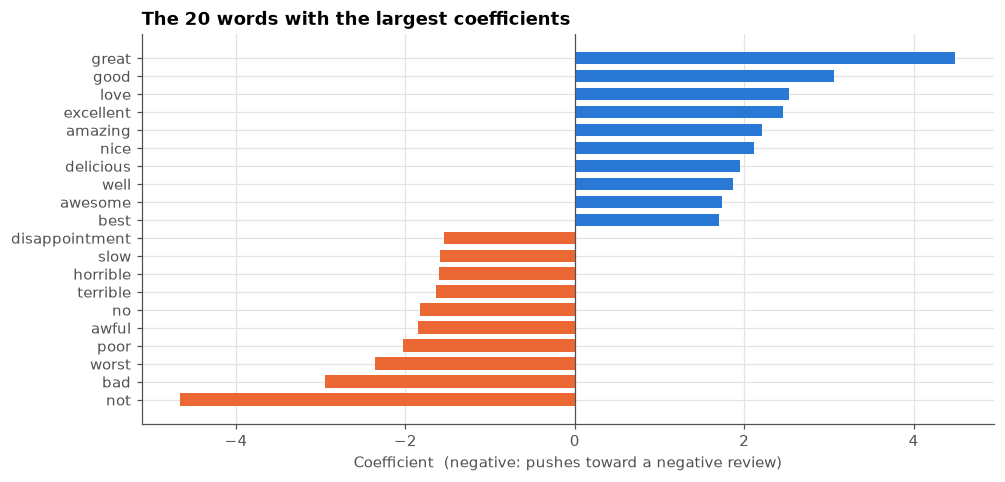

Vocabulary words that appear in only one training review: 2,168 of 3,682


In [8]:
has_negation = train["review"].str.contains(r"\b(?:not|no|nor|never)\b|n't", case=False, regex=True)
print(f"Training reviews containing a negation: {has_negation.sum():,} of {len(train):,} ({has_negation.mean():.0%})")
print(f"Share negative among those: {1 - train.loc[has_negation, 'sentiment'].mean():.0%}.  "
      f"Among the rest: {1 - train.loc[~has_negation, 'sentiment'].mean():.0%}")

CLEANING = VARIANTS["5. The original cleaning, negations protected"]
for part in (train, validation, test):
    part["clean"] = part["review"].map(lambda r: clean(r, **CLEANING))

vectorizer = TfidfVectorizer(token_pattern=WORDS, lowercase=False)
model = LogisticRegression(max_iter=2000).fit(vectorizer.fit_transform(train["clean"]), train["sentiment"])
weights = pd.Series(model.coef_[0], index=vectorizer.get_feature_names_out()).sort_values()
strongest = pd.concat([weights.head(10), weights.tail(10)])

fig, ax = plt.subplots(figsize=(10, 4.6))
ax.barh(strongest.index, strongest.values, color=[ORANGE if v < 0 else BLUE for v in strongest.values], height=0.7)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set(title="The 20 words with the largest coefficients", xlabel="Coefficient  (negative: pushes toward a negative review)")
plt.show()

in_reviews = (vectorizer.transform(train["clean"]) > 0).sum(axis=0).A1
print(f"Vocabulary words that appear in only one training review: {(in_reviews == 1).sum():,} of {len(in_reviews):,}")

Negations appear in 22% of the training reviews, and 76% of those reviews are negative, against 43% of the rest. In the fitted model, "not" has the largest coefficient of any word. More than half of the vocabulary (2,168 of 3,682 words) appears in only one training review, so the model can learn little about those words.

In [9]:
# Does the TF-IDF weighting matter here? The same model with three ways of scoring words.
scoring = {
    "TF-IDF weights": TfidfVectorizer(token_pattern=WORDS, lowercase=False),
    "Raw counts": CountVectorizer(token_pattern=WORDS, lowercase=False),
    "Present or absent": CountVectorizer(token_pattern=WORDS, lowercase=False, binary=True),
}
pd.Series({name: cross_val_score(baseline(v), train["clean"], train["sentiment"], cv=folds).mean()
           for name, v in scoring.items()}, name="cross-validated accuracy").to_frame()

,cross-validated accuracy
TF-IDF weights,0.827
Raw counts,0.821
Present or absent,0.821


The three are within about half a point of each other. These reviews are a sentence long, so a word rarely appears twice in the same review, and the weighting has little to work with.

> **In my words**
>
> I blindly used the nltk stopwords without actually inspecting their contents, or evaluating their use in the context of the work (sentiment analysis). A critical eye and attention to detail would have revealed this during the course of the analysis.
>
> The cleaning for this data made a critical error during stopword removal, which was the removal of negations. This negatively impacted the model's performance as certain removed words (such as "not") were strong indicators of review sentiment. Although stopword removal can be a useful tool situationally, it was overapplied here - negations should have been kept. As for other cleaning steps: converting to lowercase was useful and should be kept as-is; removing punctuation and lemmatizing had little effect, although in the future should not be done blindly. The lemmatization implemented here was faulty in that it was run with the defaults, considering all words a noun; this had no negative effect in practice but caused some situations where words were improperly cut short.

### The baseline to beat

The word-count model, with the chosen cleaning, scored on the validation set. The test set stays untouched until the end.

In [10]:
baseline_model = baseline().fit(train["clean"], train["sentiment"])
validation_accuracy = baseline_model.score(validation["clean"], validation["sentiment"])
standard_error = np.sqrt(validation_accuracy * (1 - validation_accuracy) / len(validation))
print(f"Always predicting the more common label: {max(validation['sentiment'].mean(), 1 - validation['sentiment'].mean()):.1%}")
print(f"Word-count baseline: {validation_accuracy:.1%} on {len(validation)} validation reviews "
      f"(give or take about {1.96 * standard_error:.1%})")
validation.assign(correct=baseline_model.predict(validation["clean"]) == validation["sentiment"]) \
    .groupby("source")["correct"].agg(reviews="size", accuracy="mean")

Always predicting the more common label: 50.1%
Word-count baseline: 83.4% on 447 validation reviews (give or take about 3.4%)


,reviews,accuracy
source,,
Amazon,149,0.852
IMDb,149,0.765
Yelp,149,0.886


The word-count baseline reaches 83.4% on the validation set, against 50% for always predicting the same label. With 447 validation reviews that figure is uncertain by about 3.4 points either way, so small differences between models later on will need care. It does better on Yelp (88.6%) and Amazon (85.2%) reviews than on IMDb (76.5%).

This is the standard the neural networks in the following sections have to beat.